In [5]:
from WERM.fixed_point_eqns import *
import numpy as np
import jax.numpy as jnp

M = lambda t: jnp.power(t, 2)
n = 100
δ = 1.0
π = jnp.ones(n)
L = 2
η = [0, 50, n-1]
ρ = jnp.eye(L)
ε = np.random.randn(n)

# μ̃, σ̃_squared, τ_squared, b = fp_linear_model(M, ρ, L, η, π, δ, n, ε)
# σ̃ = fp_linear_model_vanilla(M, δ, n, π, ε)

τ = 0.4
b = 0.9
G = np.random.randn(n)
δ * jnp.mean(jnp.power(S_prime_mapped(ε + τ * G, b, π), 2))


DeviceArray(0.41326531, dtype=float64)

### Test Vanilla Linear Model Fixed Point Equations (even with a non-uniform $\pi$, just no change point)

  0%|          | 0/7 [00:00<?, ?it/s]

δ =  1.5
σ̃ =  0.9979308908469983
Regressing on signal  0


 14%|█▍        | 1/7 [00:09<00:54,  9.03s/it]

δ =  2.0
σ̃ =  0.801945200086279
Regressing on signal  0


 29%|██▊       | 2/7 [00:15<00:38,  7.73s/it]

δ =  2.5
σ̃ =  0.768940115892466
Regressing on signal  0


... (5 outputs left out)

δ =  4.0
σ̃ =  0.6678098445002838
Regressing on signal  0


 86%|████████▌ | 6/7 [00:45<00:07,  7.50s/it]

δ =  4.5
σ̃ =  0.6793619696511504
Regressing on signal  0


100%|██████████| 7/7 [00:52<00:00,  7.54s/it]


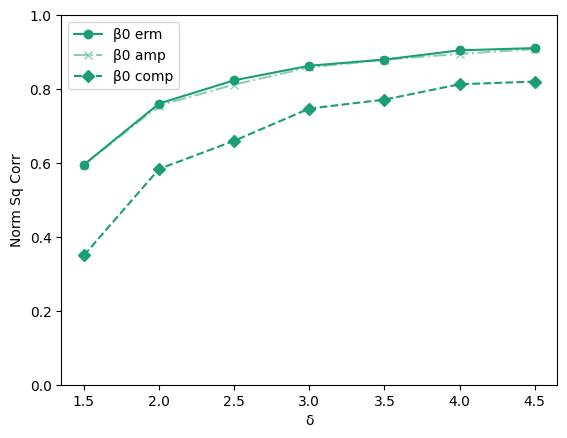

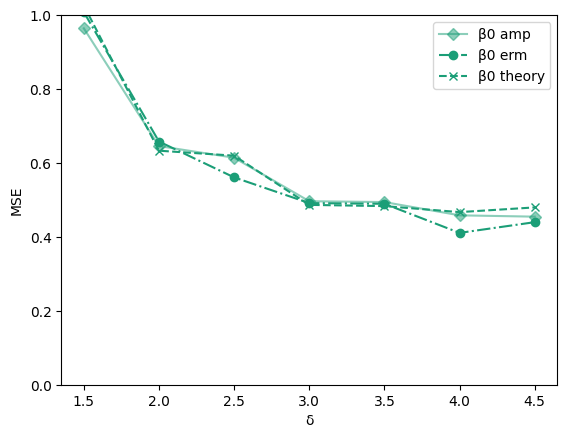

In [3]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 1 # num signals. L-1 changepoints

δ_list = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5]
noise_std = 0.5
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
# chgpt_locations = np.array([0.5])
chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
        print("C_true.shape: ", C_true.shape)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int)

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
    # ε = np.random.randn(n) * noise_std
    # y = X @ B̃[:, 0] + ε

    # --- Run Weighted ERM and compare with the fixed point equations --- #
    B̂ = np.zeros((p, L))
    for ℓ_ in range(L):

        ε = np.random.rand(n) * noise_std
        π = np.ones(n)
        σ̃ = fp_linear_model_vanilla(M, δ, noise_std)
        print("σ̃ = ", σ̃)
        β̂_amp = B̃[:, ℓ_] + σ̃ * np.random.normal(0, 1, p)

        print("Regressing on signal ", ℓ_)
        # sample_weight = ϕ[ℓ_, :]
        sample_weight = jnp.arange(n) / n
        sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
        sk_lin_reg.fit(X, y, sample_weight = sample_weight)
        # sk_lin_reg.fit(X, y)
        β̂ = sk_lin_reg.coef_

        B̂[:, ℓ_] = β̂
        erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
        amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

        comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
        comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
        erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
        amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
        G = np.random.randn(p)
        theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="-.", c=PAL[ℓ_], alpha = 0.5)
    plt.errorbar(δ_list, comparison_corr_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    # plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="D", ls="-", c=PAL[ℓ_], alpha = 0.5)
    plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

### The vanilla fixed point equation works, and tracks the behaviour of the ERM. 

# Test Linear Model Fixed Point Equations (with a change point)

  0%|          | 0/8 [00:00<?, ?it/s]

δ =  1.8
Optimization Results: x =  [1.1629017  1.36873154 1.63053473] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 12, 'njev': 1, 'fjac': array([[-0.89929917,  0.43453303,  0.049417  ],
       [-0.42267836, -0.89260304,  0.15685286],
       [-0.11226751, -0.12017016, -0.98638488]]), 'r': array([ 0.69688587, -0.58035237, -0.12675668,  0.59259862, -0.32010066,
        0.23573281]), 'qtf': array([-3.49590976e-12, -1.86654347e-10,  2.97786294e-10]), 'fvec': array([ 4.95670172e-12,  1.25479627e-11, -3.05813153e-11])}
μ̃_arr:  [0.63378485 0.36621515]
σ̃ =  1.4014575964646807
Regressing on signal  0


 12%|█▎        | 1/8 [00:09<01:05,  9.40s/it]

δ =  2.0
Optimization Results: x =  [1.07300017 1.3228696  1.2561704 ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 10, 'njev': 1, 'fjac': array([[-0.89302747,  0.44976321,  0.01466237],
       [-0.44989383, -0.89305333, -0.00716235],
       [-0.00987292,  0.01299269, -0.99986685]]), 'r': array([ 0.68224111, -0.56791663, -0.1434855 ,  0.60700864, -0.3443186 ,
        0.34721233]), 'qtf': array([4.52748318e-10, 7.61024511e-10, 1.90965726e-10]), 'fvec': array([ 1.46127555e-12,  1.49680268e-12, -1.17927890e-12])}
μ̃_arr:  [0.64766806 0.35233194]
σ̃ =  1.3414160800367152
Regressing on signal  0


 25%|██▌       | 2/8 [00:18<00:56,  9.40s/it]

δ =  2.5
Optimization Results: x =  [0.88345031 1.2190815  0.78936176] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 8, 'njev': 1, 'fjac': array([[-9.23377769e-01,  3.83892550e-01,  7.32669261e-05],
       [-3.83878807e-01, -9.23346294e-01,  8.28745464e-03],
       [-3.24914284e-03, -7.62432575e-03, -9.99965656e-01]]), 'r': array([ 0.68466839, -0.47813902, -0.19880939,  0.76228202, -0.43896082,
        0.68548614]), 'qtf': array([1.20048649e-11, 1.43308731e-11, 6.20166074e-12]), 'fvec': array([1.89848137e-14, 1.99840144e-15, 1.11022302e-16])}
μ̃_arr:  [0.67133845 0.32866155]
σ̃ =  1.1811455180311523
Regressing on signal  0


... (7 outputs left out)

δ =  4.5
Optimization Results: x =  [0.61352211 1.09305391 0.31058815] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 11, 'njev': 1, 'fjac': array([[-0.95887714,  0.2758417 , -0.06682798],
       [-0.27920715, -0.959052  ,  0.04756719],
       [ 0.0509705 , -0.06426994, -0.99663001]]), 'r': array([ 0.74027093, -0.2871665 ,  0.0405407 ,  1.02813966, -1.02031567,
        2.2152108 ]), 'qtf': array([-4.33833220e-10,  7.22192016e-11, -6.05431452e-10]), 'fvec': array([-4.60631533e-13,  7.17204074e-13, -1.63802305e-12])}
μ̃_arr:  [0.70934814 0.29065186]
σ̃ =  0.9750992046477172
Regressing on signal  0


 88%|████████▊ | 7/8 [01:09<00:10, 10.21s/it]

δ =  5.0
Optimization Results: x =  [0.60695106 1.12312171 0.26923712] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 13, 'njev': 1, 'fjac': array([[-0.9608528 ,  0.26792233, -0.07056579],
       [-0.27289357, -0.95919522,  0.07398399],
       [ 0.04786441, -0.09034468, -0.99475969]]), 'r': array([ 0.74624804, -0.25607408,  0.11420542,  1.09235885, -1.21429591,
        2.60937055]), 'qtf': array([1.02170598e-10, 6.39521621e-11, 2.14340815e-11]), 'fvec': array([ 1.33815181e-12,  1.53366209e-12, -9.11715148e-13])}
μ̃_arr:  [0.7137446 0.2862554]
σ̃ =  0.9930124760612912
Regressing on signal  0


100%|██████████| 8/8 [01:20<00:00, 10.12s/it]


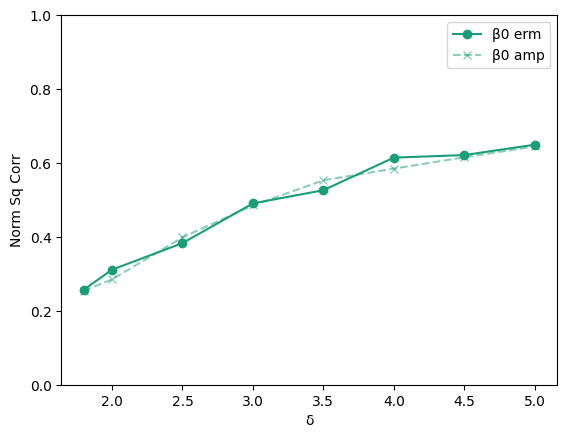

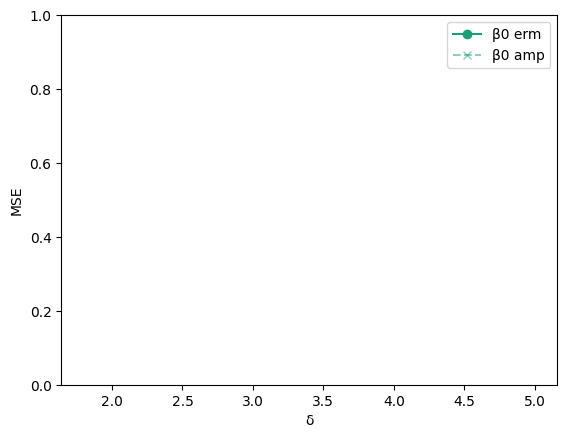

In [2]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 2 # num signals. L-1 changepoints

δ_list = [1.8, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
noise_std = 0.5
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    # --- Run Weighted ERM and compare with the fixed point equations --- #
    B̂ = np.zeros((p, L))

    ℓ_ = 0
    # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
    μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
    print("σ̃ = ", σ̃)
    β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

    print("Regressing on signal ", ℓ_)
    sample_weight = (n - np.arange(n)) / n
    sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
    sk_lin_reg.fit(X, y, sample_weight = sample_weight)
    β̂ = sk_lin_reg.coef_

    B̂[:, ℓ_] = β̂
    erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
    amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

    comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
    comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
    erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
    amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
    G = np.random.randn(p)
    theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
ℓ_ = 0
plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
# plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

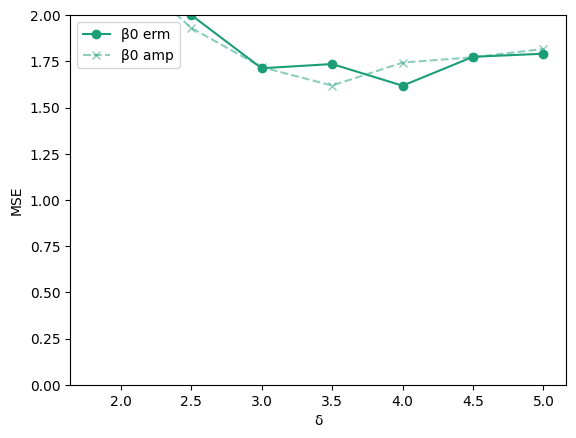

In [3]:
# MSE plots
# plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

### To try: increase num_samples, pass in jacobian to scipy optimize BFGS, re-look at everything. Noise should not be increasing with $\delta$. 

In [3]:
μ̃_arr.sum()

0.999996498954283

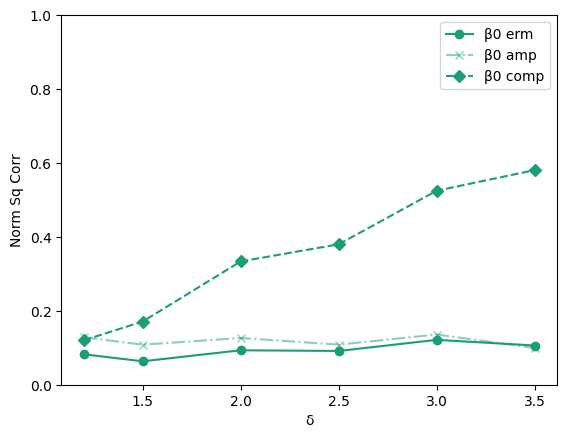

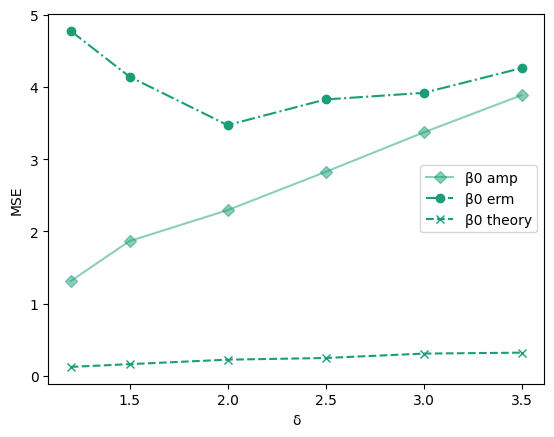

In [3]:
PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
ℓ_ = 0
plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="-.", c=PAL[ℓ_], alpha = 0.5)
plt.errorbar(δ_list, comparison_corr_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
ℓ_ = 0
# plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="D", ls="-", c=PAL[ℓ_], alpha = 0.5)
plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
# plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [5]:
μ̃_arr.sum()

0.9999776991607034